# Data Info

Feature Explanation:

* distance_from_home - the distance from home where the transaction happened.

* distance_from_last_transaction - the distance from last transaction happened.

* ratio_to_median_purchase_price - Ratio of purchased price transaction to median purchase price.

* repeat_retailer - Is the transaction happened from same retailer.

* used_chip - Is the transaction through chip (credit card).

* used_pin_number - Is the transaction happened by using PIN number.

* online_order - Is the transaction an online order.

* fraud - Is the transaction fraudulent.

Dataset Link : https://www.kaggle.com/datasets/dhanushnarayananr/credit-card-fraud

# Import Library

In [1]:
import pandas as pd
import numpy as np
%matplotlib inline
import matplotlib.pyplot as plt
import seaborn as sns


# Load Dataset

In [2]:
data = pd.read_csv('card_transdata.csv')

# PREPROCESSING DATA & EDA

In [3]:
data.head()

,distance_from_home,distance_from_last_transaction,ratio_to_median_purchase_price,repeat_retailer,used_chip,used_pin_number,online_order,fraud
0,57.877857,0.311140,1.945940,1.0,1.0,0.0,0.0,0.0
1,10.829943,0.175592,1.294219,1.0,0.0,0.0,0.0,0.0
2,5.091079,0.805153,0.427715,1.0,0.0,0.0,1.0,0.0
3,2.247564,5.600044,0.362663,1.0,1.0,0.0,1.0,0.0
4,44.190936,0.566486,2.222767,1.0,1.0,0.0,1.0,0.0


In [4]:
data.shape

(1000000, 8)

In [5]:
data.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1000000 entries, 0 to 999999
Data columns (total 8 columns):
 #   Column                          Non-Null Count    Dtype  
---  ------                          --------------    -----  
 0   distance_from_home              1000000 non-null  float64
 1   distance_from_last_transaction  1000000 non-null  float64
 2   ratio_to_median_purchase_price  1000000 non-null  float64
 3   repeat_retailer                 1000000 non-null  float64
 4   used_chip                       1000000 non-null  float64
 5   used_pin_number                 1000000 non-null  float64
 6   online_order                    1000000 non-null  float64
 7   fraud                           1000000 non-null  float64
dtypes: float64(8)
memory usage: 61.0 MB


In [8]:
data.isnull().sum()

distance_from_home                0
distance_from_last_transaction    0
ratio_to_median_purchase_price    0
repeat_retailer                   0
used_chip                         0
used_pin_number                   0
online_order                      0
fraud                             0
dtype: int64

In [9]:
data.duplicated().sum()

np.int64(0)

In [10]:
data.describe()

,distance_from_home,distance_from_last_transaction,ratio_to_median_purchase_price,repeat_retailer,used_chip,used_pin_number,online_order,fraud
count,1000000.000000,1000000.000000,1000000.000000,1000000.000000,1000000.000000,1000000.000000,1000000.000000,1000000.000000
mean,26.628792,5.036519,1.824182,0.881536,0.350399,0.100608,0.650552,0.087403
std,65.390784,25.843093,2.799589,0.323157,0.477095,0.300809,0.476796,0.282425
min,0.004874,0.000118,0.004399,0.000000,0.000000,0.000000,0.000000,0.000000
25%,3.878008,0.296671,0.475673,1.000000,0.000000,0.000000,0.000000,0.000000
50%,9.967760,0.998650,0.997717,1.000000,0.000000,0.000000,1.000000,0.000000
75%,25.743985,3.355748,2.096370,1.000000,1.000000,0.000000,1.000000,0.000000
max,10632.723672,11851.104565,267.802942,1.000000,1.000000,1.000000,1.000000,1.000000


In [11]:
data['fraud'].value_counts()

fraud
0.0    912597
1.0     87403
Name: count, dtype: int64

In [12]:
data['fraud'].value_counts(normalize=True) * 100

fraud
0.0    91.2597
1.0     8.7403
Name: proportion, dtype: float64

We have imbalance data

In [13]:
data.groupby('fraud').mean()

,distance_from_home,distance_from_last_transaction,ratio_to_median_purchase_price,repeat_retailer,used_chip,used_pin_number,online_order
fraud,,,,,,,
0.0,22.832976,4.301391,1.423642,0.881672,0.359402,0.109944,0.622225
1.0,66.261876,12.712185,6.006323,0.880119,0.256399,0.003123,0.946318


# Visualization

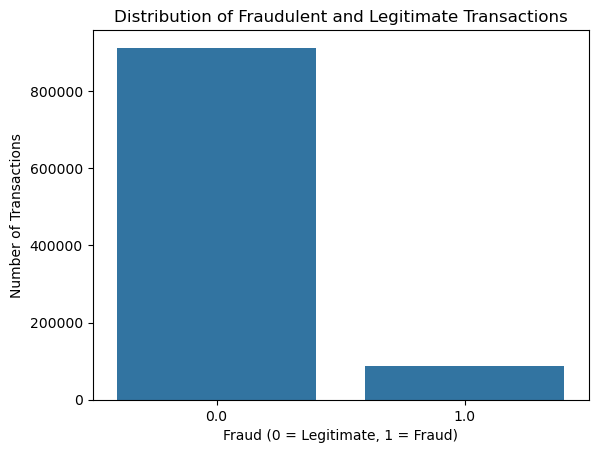

In [14]:
sns.countplot(data=data, x='fraud')
plt.title('Distribution of Fraudulent and Legitimate Transactions')
plt.xlabel('Fraud (0 = Legitimate, 1 = Fraud)')
plt.ylabel('Number of Transactions')
plt.show()

fraud represents a very small percentage, the dataset is imbalanced. This matters later when choosing evaluation metrics such as precision, recall and F1-score.

In [15]:
numerical_features = [
    'distance_from_home',
    'distance_from_last_transaction',
    'ratio_to_median_purchase_price'
]

binary_features = [
    'repeat_retailer',
    'used_chip',
    'used_pin_number',
    'online_order'
]

target = 'fraud'

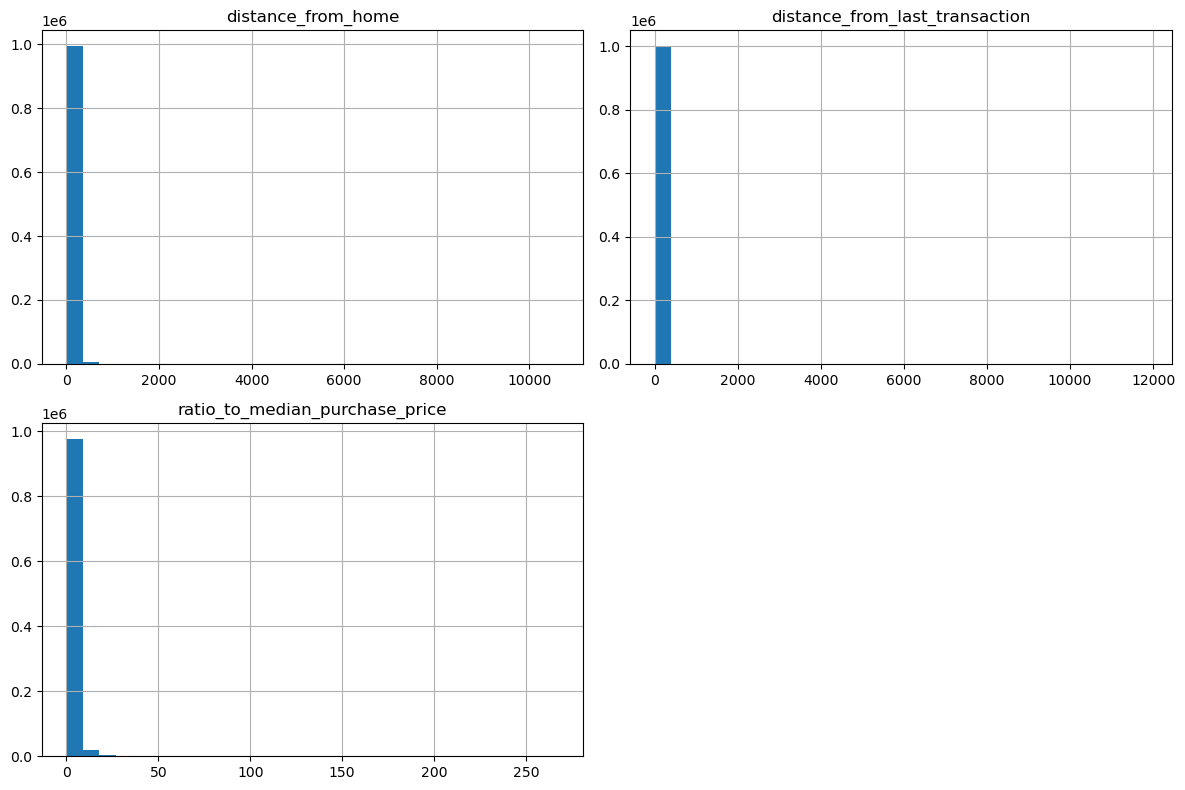

In [16]:
data[numerical_features].hist(
    bins=30,
    figsize=(12, 8)
)

plt.tight_layout()
plt.show()

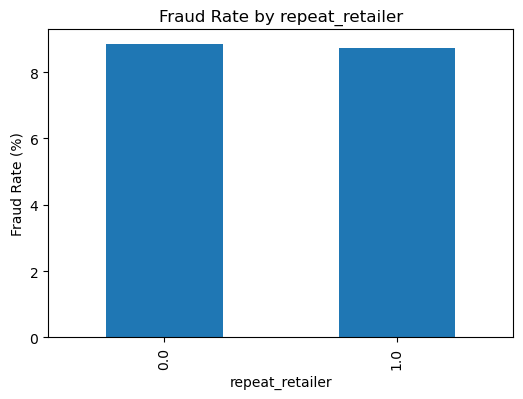

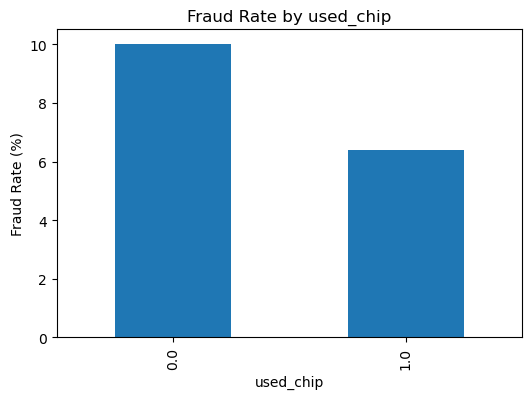

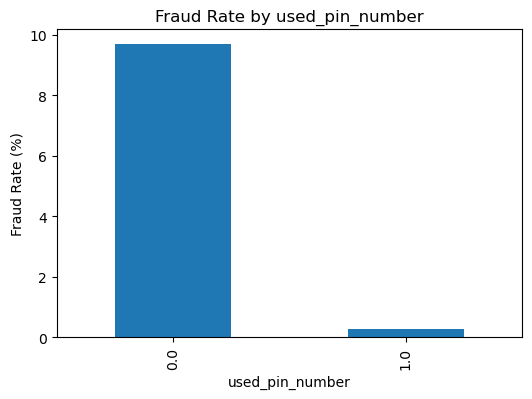

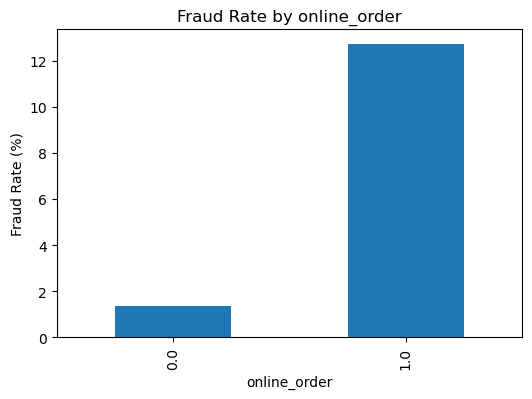

In [17]:
for column in binary_features:

    plt.figure(figsize=(6, 4))

    fraud_rate = (data.groupby(column)['fraud'].mean()) * 100


    fraud_rate.plot(kind='bar')

    plt.title(f'Fraud Rate by {column}')
    plt.xlabel(column)
    plt.ylabel('Fraud Rate (%)')



    plt.show()

As we see the the fredulant transaction is high by online_order, used_chip and repeat_retailer

In [18]:
#Seperating the data
legit = data[data.fraud == 0]
fraud = data[data.fraud == 1]

In [22]:
print(legit.shape)
print(fraud.shape)

(912597, 8)
(87403, 8)


In [20]:
legit.ratio_to_median_purchase_price.describe()

count    912597.000000
mean          1.423642
std           1.946152
min           0.004399
25%           0.449768
50%           0.913950
75%           1.788918
max         267.802942
Name: ratio_to_median_purchase_price, dtype: float64

In [21]:
fraud.ratio_to_median_purchase_price.describe()

count    87403.000000
mean         6.006323
std          5.564320
min          0.011966
25%          3.500270
50%          5.071294
75%          7.331222
max        266.689692
Name: ratio_to_median_purchase_price, dtype: float64

# Undersampling

**Build a sample dataset that have similiar distribution of normal transactions and fraudulent transcations**

* No of Fraud Transaction = 87403
* No of Normal/Legit Transcaction = 912597

In [23]:
legit_sample= legit.sample(n=87403)

**Concatenating two DataFrames**

In [24]:
new_data = pd.concat([legit_sample,fraud], axis=0)

In [25]:
new_data.head()

,distance_from_home,distance_from_last_transaction,ratio_to_median_purchase_price,repeat_retailer,used_chip,used_pin_number,online_order,fraud
785232,6.342005,0.119828,0.937909,1.0,0.0,0.0,1.0,0.0
594544,16.323148,4.002551,0.428147,1.0,0.0,0.0,0.0,0.0
330607,9.043091,1.601350,2.447444,1.0,1.0,0.0,1.0,0.0
460832,2.909975,3.781715,0.432479,1.0,0.0,0.0,1.0,0.0
701124,4.949883,0.609332,1.145569,1.0,0.0,0.0,1.0,0.0


In [26]:
new_data.tail()

,distance_from_home,distance_from_last_transaction,ratio_to_median_purchase_price,repeat_retailer,used_chip,used_pin_number,online_order,fraud
999908,45.296658,0.882736,8.856861,1.0,0.0,0.0,1.0,1.0
999916,167.139756,0.282253,0.308468,1.0,0.0,0.0,1.0,1.0
999919,124.640118,0.004416,0.434885,1.0,0.0,0.0,1.0,1.0
999939,51.412900,3.429330,29.914254,1.0,0.0,0.0,1.0,1.0
999949,15.724799,1.875906,11.009366,1.0,1.0,0.0,1.0,1.0


In [27]:
new_data['fraud'].value_counts()

fraud
0.0    87403
1.0    87403
Name: count, dtype: int64

In [29]:
new_data.groupby('fraud').mean()

,distance_from_home,distance_from_last_transaction,ratio_to_median_purchase_price,repeat_retailer,used_chip,used_pin_number,online_order
fraud,,,,,,,
0.0,22.674871,4.215326,1.409594,0.881800,0.358340,0.110889,0.623445
1.0,66.261876,12.712185,6.006323,0.880119,0.256399,0.003123,0.946318


**Splitting dataset**

In [30]:
X = new_data.drop(columns= target , axis=1)
Y = new_data[target]

In [31]:
X

,distance_from_home,distance_from_last_transaction,ratio_to_median_purchase_price,repeat_retailer,used_chip,used_pin_number,online_order
785232,6.342005,0.119828,0.937909,1.0,0.0,0.0,1.0
594544,16.323148,4.002551,0.428147,1.0,0.0,0.0,0.0
330607,9.043091,1.601350,2.447444,1.0,1.0,0.0,1.0
460832,2.909975,3.781715,0.432479,1.0,0.0,0.0,1.0
701124,4.949883,0.609332,1.145569,1.0,0.0,0.0,1.0
...,...,...,...,...,...,...,...
999908,45.296658,0.882736,8.856861,1.0,0.0,0.0,1.0
999916,167.139756,0.282253,0.308468,1.0,0.0,0.0,1.0
999919,124.640118,0.004416,0.434885,1.0,0.0,0.0,1.0
999939,51.412900,3.429330,29.914254,1.0,0.0,0.0,1.0


In [32]:
Y

785232    0.0
594544    0.0
330607    0.0
460832    0.0
701124    0.0
         ... 
999908    1.0
999916    1.0
999919    1.0
999939    1.0
999949    1.0
Name: fraud, Length: 174806, dtype: float64

In [34]:
from sklearn.model_selection import train_test_split

X_train, X_test, Y_train, Y_test = train_test_split(X, Y, test_size=0.2, stratify=Y, random_state=2)

In [36]:
print(X_train.shape, X_test.shape)

(139844, 7) (34962, 7)


# Model Training

* Logistic Regression

In [42]:
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score

In [39]:
model = LogisticRegression()

In [40]:
#Train using LogisticRegg with train data
model.fit(X_train, Y_train)

C:\Users\User\anaconda4\Lib\site-packages\sklearn\linear_model\_logistic.py:473: ConvergenceWarning: lbfgs failed to converge after 100 iteration(s) (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT

Increase the number of iterations to improve the convergence (max_iter=100).
You might also want to scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(


,penalty,'l2'
,dual,False
,tol,0.0001
,C,1.0
,fit_intercept,True
,intercept_scaling,1
,class_weight,None
,random_state,None
,solver,'lbfgs'
,max_iter,100
,multi_class,'deprecated'


**Model Eval**

* Accuracy Score

In [43]:
#Train data score
X_train_prediction = model.predict(X_train)
training_data_accuracy= accuracy_score(X_train_prediction, Y_train)

In [44]:
print('Accuracy on training data : ',training_data_accuracy)

Accuracy on training data :  0.9402977603615458


In [45]:
# Accuracy on the test data
X_test_prediction = model.predict(X_test)
test_data_accuracy = accuracy_score(X_test_prediction, Y_test)

In [46]:
print('Accuracy on test data : ',test_data_accuracy)

Accuracy on test data :  0.9390195068931984


*Note: if the accuracy on the train data are very different on the test data, the model either be overfitted or underfitted* 

# Saving the trained model

In [47]:
import pickle

In [48]:
filename = 'fraud_detection_model.sav'
pickle.dump(model,open(filename, 'wb'))